# TA-04: Peramalan Pendapatan Harian E-Commerce dengan LSTM

**Target:** `TotalPrice` dijumlahkan per hari (pendapatan harian).
**Dataset:** `ecommerce_orders.csv` (pemisah `;`, desimal koma).

Alur: (1) EDA dan preprocessing, (2) model LSTM, (3) evaluasi, (5) penyimpanan model dan scaler, lalu dilanjutkan ke aplikasi Flask (`app.py`).

> Jalankan semua sel dari atas ke bawah. Setelah selesai, folder `artifacts/` akan berisi file yang dibutuhkan aplikasi Flask.

## Tahap 1. EDA dan Preprocessing

In [1]:
import json, os, random, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

# ---- Konfigurasi ----
CSV_PATH = "ecommerce_orders.csv"
TARGET = "TotalPrice"
EXCLUDE_STATUS = []        # contoh: ["Cancelled", "Returned"] untuk hanya menghitung pesanan yang tidak batal/retur
TIMESTEPS = 30             # pakai 30 hari terakhir untuk memprediksi hari berikutnya
TRAIN_RATIO = 0.8
ARTIFACT_DIR = "artifacts"
os.makedirs(ARTIFACT_DIR, exist_ok=True)

In [2]:
# File memakai pemisah titik koma dan koma sebagai desimal
df = pd.read_csv(CSV_PATH, sep=";", decimal=",", parse_dates=["Date"])
print("Ukuran data:", df.shape)
display(df.head())
df.info()

Ukuran data: (1200, 14)


,OrderID,Date,CustomerID,Product,Quantity,UnitPrice,ShippingAddress,PaymentMethod,OrderStatus,TrackingNumber,ItemsInCart,CouponCode,ReferralSource,TotalPrice
0,ORD200000,2023-01-04,C72649,Monitor,5,570.62,928 Main St,Debit Card,Shipped,TRK37947903,7,SAVE10,Instagram,2853.10
1,ORD200001,2024-08-23,C75739,Phone,2,151.35,823 Main St,Online,Shipped,TRK91186779,3,SAVE10,Referral,302.70
2,ORD200002,2024-02-27,C81728,Tablet,5,550.68,512 Main St,Credit Card,Cancelled,TRK42903982,8,FREESHIP,Email,2753.40
3,ORD200003,2023-10-15,C33540,Chair,1,273.19,275 Main St,Debit Card,Returned,TRK62788070,5,SAVE10,Facebook,273.19
4,ORD200004,2025-05-08,C81840,Printer,4,626.01,668 Main St,Online,Delivered,TRK29241424,8,SAVE10,Email,2504.04


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   OrderID          1200 non-null   object        
 1   Date             1200 non-null   datetime64[ns]
 2   CustomerID       1200 non-null   object        
 3   Product          1200 non-null   object        
 4   Quantity         1200 non-null   int64         
 5   UnitPrice        1200 non-null   float64       
 6   ShippingAddress  1200 non-null   object        
 7   PaymentMethod    1200 non-null   object        
 8   OrderStatus      1200 non-null   object        
 9   TrackingNumber   1200 non-null   object        
 10  ItemsInCart      1200 non-null   int64         
 11  CouponCode       891 non-null    object        
 12  ReferralSource   1200 non-null   object        
 13  TotalPrice       1200 non-null   float64       
dtypes: datetime64[ns](1), float64(2), int64(

In [3]:
# Pemeriksaan kualitas data
kosong = df.isna().sum()
print("Kolom dengan nilai kosong:\n", kosong[kosong > 0], "\n")
print("OrderID duplikat      :", df["OrderID"].duplicated().sum())
print("Rentang tanggal       :", df["Date"].min().date(), "sampai", df["Date"].max().date())
print("TotalPrice != Qty*Harga:", ((df["Quantity"] * df["UnitPrice"] - df["TotalPrice"]).abs() > 0.02).sum())
print()
print(df["OrderStatus"].value_counts())

Kolom dengan nilai kosong:
 CouponCode    309
dtype: int64 

OrderID duplikat      : 0
Rentang tanggal       : 2023-01-01 sampai 2025-06-30
TotalPrice != Qty*Harga: 0

OrderStatus
Cancelled    250
Returned     247
Pending      237
Shipped      235
Delivered    231
Name: count, dtype: int64


**Membentuk deret waktu harian.** Data awal berupa satu baris per pesanan, bukan per hari. Pesanan dijumlahkan per tanggal. Hari tanpa pesanan **tidak muncul** di data, jadi harus diisi 0 agar jarak antar timestep selalu 1 hari (syarat LSTM).

In [4]:
sales = df[~df["OrderStatus"].isin(EXCLUDE_STATUS)]
daily = sales.groupby("Date")[TARGET].sum()

full_index = pd.date_range(daily.index.min(), daily.index.max(), freq="D")
series = daily.reindex(full_index, fill_value=0.0).rename("revenue")
series.index.name = "Date"

print("Jumlah hari kalender      :", len(series))
print("Hari tanpa pesanan (=0)   :", int((series == 0).sum()))
display(series.describe())

Jumlah hari kalender      : 912
Hari tanpa pesanan (=0)   : 241


count     912.000000
mean     1386.800395
std      1532.101735
min         0.000000
25%         0.000000
50%       895.355000
75%      2272.597500
max      9290.490000
Name: revenue, dtype: float64

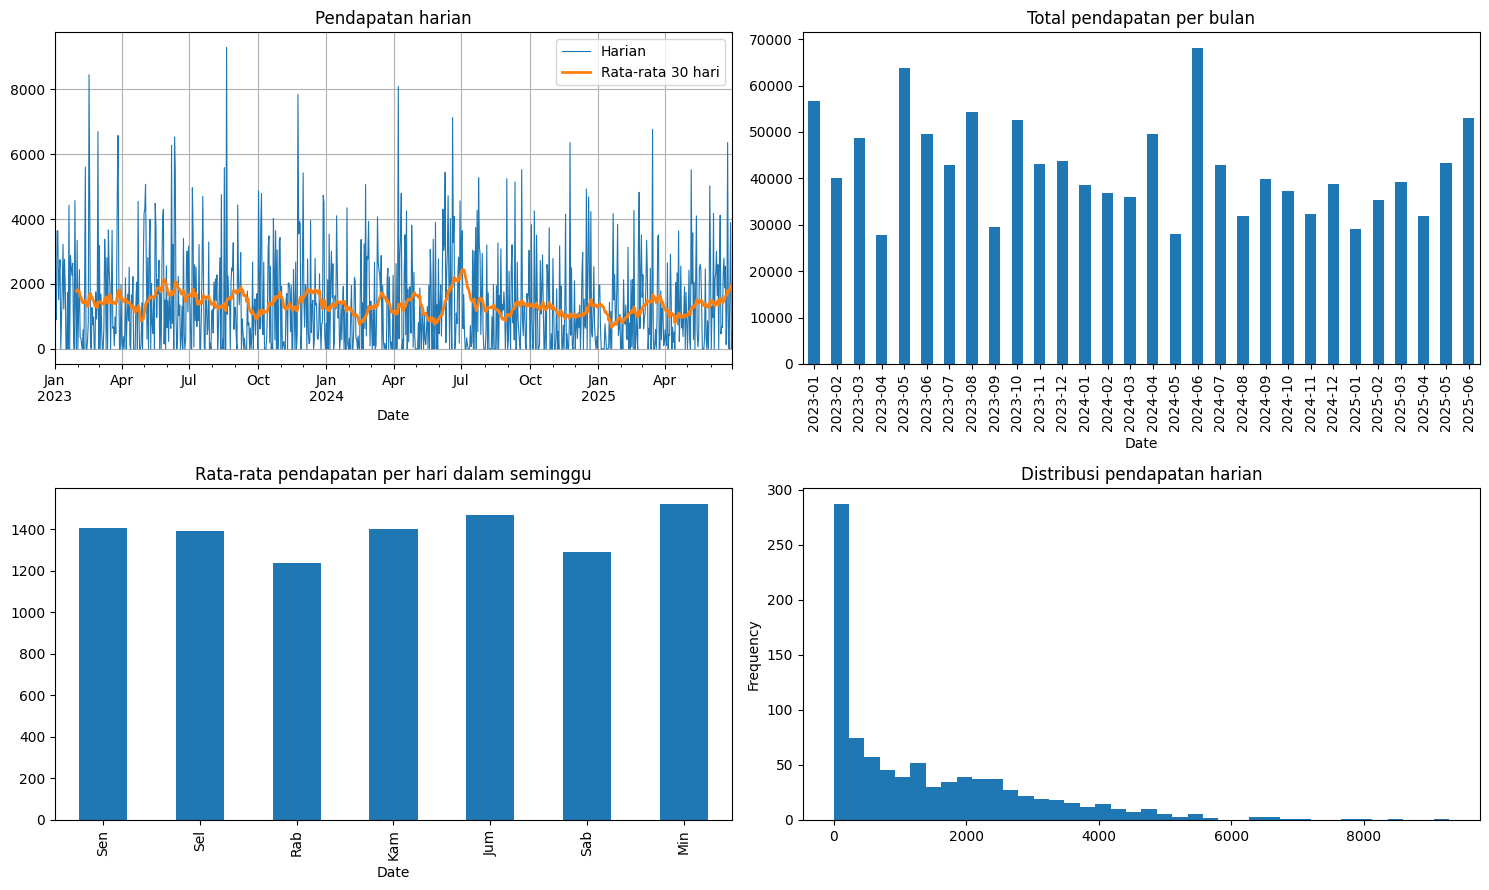

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))

series.plot(ax=axes[0, 0], lw=0.8, label="Harian")
series.rolling(30).mean().plot(ax=axes[0, 0], lw=2, label="Rata-rata 30 hari")
axes[0, 0].set_title("Pendapatan harian"); axes[0, 0].legend(); axes[0, 0].grid(True)

series.resample("ME").sum().plot(kind="bar", ax=axes[0, 1])
axes[0, 1].set_title("Total pendapatan per bulan")
axes[0, 1].set_xticklabels([d.strftime("%Y-%m") for d in series.resample("ME").sum().index], rotation=90)

hari = ["Sen", "Sel", "Rab", "Kam", "Jum", "Sab", "Min"]
series.groupby(series.index.dayofweek).mean().rename(dict(enumerate(hari))).plot(kind="bar", ax=axes[1, 0])
axes[1, 0].set_title("Rata-rata pendapatan per hari dalam seminggu")

series.plot(kind="hist", bins=40, ax=axes[1, 1])
axes[1, 1].set_title("Distribusi pendapatan harian")

plt.tight_layout(); plt.show()

In [6]:
# Apakah masa lalu membantu menebak hari ini? Autokorelasi mendekati 0 berarti hampir tidak.
for lag in (1, 7, 14, 30):
    print(f"Autokorelasi lag {lag:>2}: {series.autocorr(lag):+.3f}")

Autokorelasi lag  1: +0.018
Autokorelasi lag  7: +0.054
Autokorelasi lag 14: -0.004
Autokorelasi lag 30: -0.083


**Interpretasi EDA (isi dengan bahasa sendiri setelah melihat grafik):**
- Tren: ...
- Musiman (mingguan/bulanan): ...
- Nilai autokorelasi: ... (nilai mendekati 0 berarti pendapatan hari ini hampir tidak dipengaruhi hari-hari sebelumnya, sehingga model sulit mengalahkan tebakan rata-rata)
- Hari tanpa pesanan: ...

**Split, scaling, dan windowing.** Urutan yang benar untuk time series:
1. Bagi data **menurut waktu** (80% awal untuk latih, 20% akhir untuk uji), tanpa diacak.
2. `MinMaxScaler` hanya di-*fit* pada data latih agar tidak ada kebocoran informasi dari masa depan.
3. Bentuk window: 30 hari terakhir menjadi `X`, hari berikutnya menjadi `y`.
4. Data uji tetap memakai 30 hari sebelumnya sebagai konteks, tetapi target `y` hanya dari periode uji.

In [7]:
values = series.values.reshape(-1, 1)
split_idx = int(len(values) * TRAIN_RATIO)        # indeks hari pertama data uji

scaler = MinMaxScaler(feature_range=(0, 1))
scaler.fit(values[:split_idx])                    # hanya data latih
scaled = scaler.transform(values)

def make_windows(arr, timesteps):
    X, y = [], []
    for i in range(timesteps, len(arr)):
        X.append(arr[i - timesteps:i, 0])
        y.append(arr[i, 0])
    X, y = np.array(X), np.array(y)
    return X.reshape(X.shape[0], X.shape[1], 1), y   # (samples, timesteps, features)

X, y = make_windows(scaled, TIMESTEPS)

# window ke-j memprediksi hari ke-(j + TIMESTEPS)
cut = split_idx - TIMESTEPS
X_train, y_train = X[:cut], y[:cut]
X_test,  y_test  = X[cut:], y[cut:]

test_dates = series.index[split_idx:]
assert len(test_dates) == len(y_test)

print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_test :", X_test.shape,  "| y_test :", y_test.shape)
print("Periode latih:", series.index[0].date(), "->", series.index[split_idx - 1].date())
print("Periode uji  :", test_dates[0].date(), "->", test_dates[-1].date())

X_train: (699, 30, 1) | y_train: (699,)
X_test : (183, 30, 1) | y_test : (183,)
Periode latih: 2023-01-01 -> 2024-12-29
Periode uji  : 2024-12-30 -> 2025-06-30


## Tahap 2. Pengembangan Model LSTM

In [8]:
model = Sequential([
    Input(shape=(TIMESTEPS, 1)),
    LSTM(64, return_sequences=True),
    Dropout(0.2),
    LSTM(32, return_sequences=False),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1),
])
model.compile(optimizer="adam", loss="mean_squared_error")
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 30, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,857 (116.63 KB)

 Trainable params: 29,857 (116.63 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
early_stop = EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)

history = model.fit(
    X_train, y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.1,      # 10% bagian akhir data latih (urutan waktu terjaga)
    callbacks=[early_stop],
    verbose=1,
)

Epoch 1/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 8s 84ms/step - loss: 0.0426 - val_loss: 0.0238
Epoch 2/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - loss: 0.0323 - val_loss: 0.0237
Epoch 3/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - loss: 0.0313 - val_loss: 0.0238
Epoch 4/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - loss: 0.0314 - val_loss: 0.0235
Epoch 5/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - loss: 0.0312 - val_loss: 0.0236
Epoch 6/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0312 - val_loss: 0.0237
Epoch 7/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - loss: 0.0309 - val_loss: 0.0238
Epoch 8/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0314 - val_loss: 0.0236
Epoch 9/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0310 - val_loss: 0.0238
Epoch 10/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0313 - val_loss: 0.0239
Epoch 11/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - loss: 0.0308 - val_loss: 0.0239
Epoch 12/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step

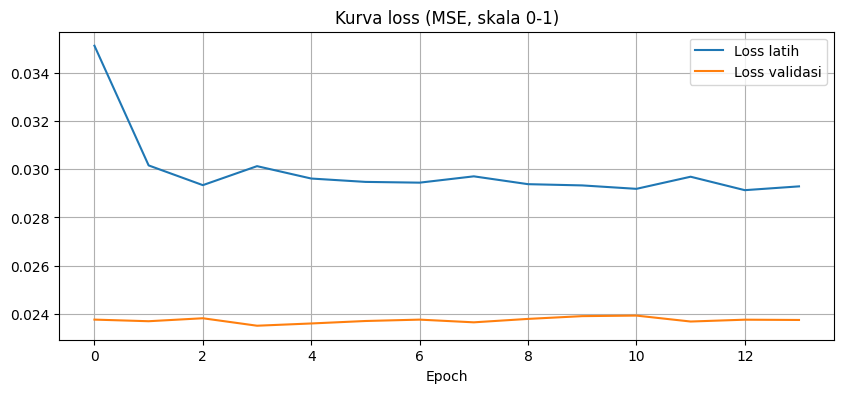

In [10]:
plt.figure(figsize=(10, 4))
plt.plot(history.history["loss"], label="Loss latih")
plt.plot(history.history["val_loss"], label="Loss validasi")
plt.title("Kurva loss (MSE, skala 0-1)"); plt.xlabel("Epoch"); plt.legend(); plt.grid(True)
plt.show()

**Cara membaca kurva loss:** loss latih turun tetapi loss validasi mendatar atau naik berarti *overfitting*. `EarlyStopping` menghentikan pelatihan dan mengembalikan bobot terbaik.

## Tahap 3. Evaluasi Model

In [11]:
pred_scaled = model.predict(X_test, verbose=0)

# Inverse transform: kembalikan ke skala pendapatan asli
y_pred = scaler.inverse_transform(pred_scaled).flatten()
y_pred = np.clip(y_pred, 0, None)                     # pendapatan tidak mungkin negatif
y_true = scaler.inverse_transform(y_test.reshape(-1, 1)).flatten()

def evaluate(true, pred):
    mse = mean_squared_error(true, pred)
    return {"MAE": mean_absolute_error(true, pred), "MSE": mse, "RMSE": float(np.sqrt(mse))}

lstm_metrics = evaluate(y_true, y_pred)
print({k: round(v, 2) for k, v in lstm_metrics.items()})

{'MAE': 1103.04, 'MSE': 1882193.55, 'RMSE': 1371.93}


**Pembanding (baseline).** LSTM hanya berguna jika lebih baik daripada tebakan sederhana. Empat baseline dihitung pada hari uji yang sama.

In [12]:
actual_test = series.iloc[split_idx:]
baselines = {
    "Naive (hari kemarin)": series.shift(1).iloc[split_idx:],
    "Rata-rata 7 hari":     series.rolling(7).mean().shift(1).iloc[split_idx:],
    "Rata-rata 30 hari":    series.rolling(30).mean().shift(1).iloc[split_idx:],
    "Rata-rata data latih": pd.Series(series.iloc[:split_idx].mean(), index=actual_test.index),
}

rows = {name: evaluate(actual_test.values, p.values) for name, p in baselines.items()}
rows["LSTM"] = lstm_metrics
comparison = pd.DataFrame(rows).T.round(2).sort_values("RMSE")
display(comparison)

,MAE,MSE,RMSE
LSTM,1103.04,1882193.55,1371.93
Rata-rata data latih,1143.78,1915384.75,1383.97
Rata-rata 30 hari,1121.48,1975234.33,1405.43
Rata-rata 7 hari,1098.20,2028338.17,1424.20
Naive (hari kemarin),1419.41,3681631.31,1918.76


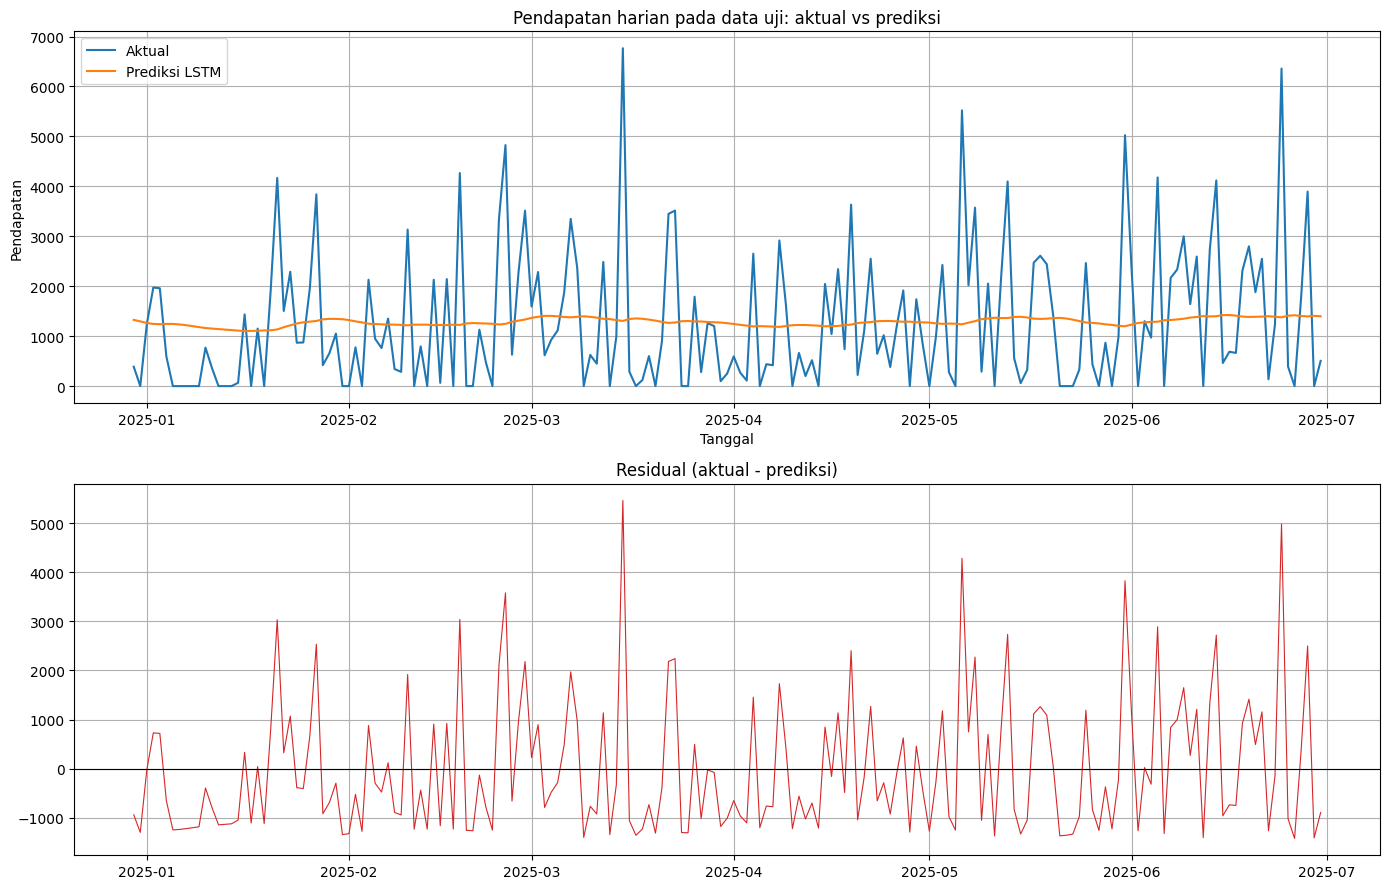

In [13]:
fig, axes = plt.subplots(2, 1, figsize=(14, 9))

axes[0].plot(test_dates, y_true, label="Aktual", color="tab:blue")
axes[0].plot(test_dates, y_pred, label="Prediksi LSTM", color="tab:orange")
axes[0].set_title("Pendapatan harian pada data uji: aktual vs prediksi")
axes[0].set_xlabel("Tanggal"); axes[0].set_ylabel("Pendapatan"); axes[0].legend(); axes[0].grid(True)

axes[1].plot(test_dates, y_true - y_pred, color="tab:red", lw=0.8)
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set_title("Residual (aktual - prediksi)"); axes[1].grid(True)

plt.tight_layout(); plt.show()

**Interpretasi hasil (isi setelah menjalankan):**
- Nilai MAE / MSE / RMSE LSTM: ...
- Apakah LSTM lebih baik daripada baseline pada tabel perbandingan? Jika tidak, jelaskan kemungkinan penyebabnya (autokorelasi rendah, banyak hari bernilai 0, data sedikit, satu fitur saja).
- Bentuk garis prediksi dibanding garis aktual (halus atau mengikuti lonjakan, adakah lag): ...
- Konteks RMSE terhadap rata-rata pendapatan harian: ...

## Tahap 5. Penyimpanan Model dan Scaler

In [14]:
# Model Keras disimpan dalam format .keras; scaler disimpan dengan Joblib
model.save(f"{ARTIFACT_DIR}/lstm_model.keras")
joblib.dump(scaler, f"{ARTIFACT_DIR}/scaler.joblib")

# Data untuk aplikasi Flask
series.reset_index().to_csv(f"{ARTIFACT_DIR}/series.csv", index=False)
pd.DataFrame({"Date": test_dates, "actual": y_true, "predicted": y_pred}).to_csv(
    f"{ARTIFACT_DIR}/test_predictions.csv", index=False)

meta = {
    "target": "Pendapatan harian (TotalPrice)",
    "timesteps": TIMESTEPS,
    "exclude_status": EXCLUDE_STATUS,
    "last_date": str(series.index[-1].date()),
    "last_window": [float(v) for v in series.values[-TIMESTEPS:]],
    "train_period": [str(series.index[0].date()), str(series.index[split_idx - 1].date())],
    "test_period": [str(test_dates[0].date()), str(test_dates[-1].date())],
    "metrics": {k: float(v) for k, v in lstm_metrics.items()},
    "baselines": {n: {k: float(v) for k, v in r.items()} for n, r in comparison.to_dict("index").items()},
    "versions": {"python": sys.version.split()[0], "tensorflow": tf.__version__,
                 "numpy": np.__version__, "pandas": pd.__version__},
}
with open(f"{ARTIFACT_DIR}/meta.json", "w") as f:
    json.dump(meta, f, indent=2)

print(sorted(os.listdir(ARTIFACT_DIR)))
print("Versi saat pelatihan:", meta["versions"])

['lstm_model.keras', 'meta.json', 'scaler.joblib', 'series.csv', 'test_predictions.csv']
Versi saat pelatihan: {'python': '3.10.9', 'tensorflow': '2.16.1', 'numpy': '1.26.4', 'pandas': '2.2.0'}


> Setelah sel ini selesai, unduh folder `artifacts/` (di Colab: klik kanan folder, atau `!zip -r artifacts.zip artifacts` lalu unduh) dan letakkan di folder proyek Flask, sejajar dengan `app.py`.
> Pasang **versi TensorFlow yang sama** dengan yang tercetak di atas pada `requirements.txt`, karena model `.keras` bisa gagal dimuat jika versinya berbeda jauh.

In [15]:
# Uji cepat: muat ulang model dan scaler dari file, hasilnya harus sama
from tensorflow.keras.models import load_model
m2 = load_model(f"{ARTIFACT_DIR}/lstm_model.keras")
s2 = joblib.load(f"{ARTIFACT_DIR}/scaler.joblib")
p2 = s2.inverse_transform(m2.predict(X_test[:5], verbose=0)).flatten()
print("Selisih maksimum vs prediksi awal:", float(np.abs(p2 - scaler.inverse_transform(pred_scaled[:5]).flatten()).max()))

Selisih maksimum vs prediksi awal: 0.0
